In [1]:
import PythonicDISORT
import numpy as np
import matplotlib.pyplot as plt
from math import pi

Previously saved reference solutions will be loaded if F2PY-wrapped Stamnes' DISORT is unavailable. With Stamnes' DISORT available, set `save_results = True` to (re)generate the saved reference solutions `Stamnes_results/PS_test.npz` which `PS_test.py` uses.

In [2]:
disort_is_installed = True
try:
    import disort
    print("Stamnes' DISORT imported.")
except ImportError:
    disort_is_installed = False
    print("Stamnes' DISORT unavailable. Cached results will be used.")

save_results = False  # Set to True to (re)generate Stamnes_results/PS_test.npz

Stamnes' DISORT imported.


# Table of Contents
* [Setup](#Setup)
* [Case A](#Case-A)
* [Case B](#Case-B)
* [Case C](#Case-C)
* [Saving the results](#Saving-the-results)
* [Before and after the correction](#Before-and-after-the-correction)

# Test Problem PS: Pseudo-spherical correction

When the sun is low, a plane-parallel atmosphere overestimates the path of the direct beam through the atmosphere, which is in truth a spherical shell. The pseudo-spherical correction, which is enabled by passing the radii of the layer boundaries `radii_arr` to `pydisort`, attenuates the direct beam along its path through the spherical shell but otherwise treats the atmosphere as plane-parallel (see section 4.2 of the Comprehensive Documentation). We compare it against that of Stamnes' DISORT (`DO_PSEUDO_SPHERE = TRUE`), whose inputs are the radius of the planet `EARTH_RADIUS` and the altitudes of the layer boundaries `H_LYR`; we pass their sums as `radii_arr`. The sun is 5 degrees above the horizon in every case.

* Cases A and B: six layers between an altitude of 60 km and a Lambertian surface, with Rayleigh-like (A) and Henyey-Greenstein (B) scattering. Case B is delta-M scaled.
* Case C: test problem 16 of Stamnes' DISORT (`disotest.f90`), a 13-layer Rayleigh atmosphere at 412 nm between an altitude of 70 km and a black surface, with nearly conservative scattering and 30 streams. That test problem evaluates only the upward intensities at the top of the atmosphere and has no reference values; we also compare both hemispheres (including the direction of the beam), depths down to the surface, the fluxes and the intensities at the quadrature nodes. Test problem PS thereby subsumes test problem 16.

In each case we compare the fluxes, the intensities at the quadrature nodes, and the intensities at other polar angles (`interpolate_mu=True`), all at several $\tau$ and $\phi$. `PS_test.py` runs the same comparisons and also checks the plane-parallel limits, the direct beam against the geometry of the spherical shells, the $\tau$-derivatives and antiderivatives, and the input checks. The last section of this notebook shows what the correction changes.

# Setup

In [3]:
earth_radius = 6371  # km; Stamnes' DISORT: EARTH_RADIUS
mu0 = np.cos(85 * pi / 180)  # The sun is 5 degrees above the horizon
I0 = 1

if disort_is_installed:
    results = {}  # Filled case by case below
else:
    # Load saved results from Stamnes' DISORT
    results = dict(np.load("Stamnes_results/PS_test.npz"))

solutions = {}  # PythonicDISORT's solutions, for the last section

In [4]:
def run_disort(tau_arr, omega_arr, NQuad, Leg_coeffs_all, phi0, albedo, altitudes, umu, phi, utau, mu0=mu0):
    """Stamnes' DISORT with DO_PSEUDO_SPHERE = TRUE, a Lambertian surface and USRANG = USRTAU = TRUE.
    Returns RFLDIR, RFLDN, FLUP and UU."""
    nlyr = len(tau_arr)
    nstr = NQuad
    numu = len(umu)
    nphi = len(phi)
    ntau = len(utau)
    usrang = True
    usrtau = True
    ibcnd = 0
    onlyfl = False
    prnt = np.array([False, False, False, False, False])  # Prints to CMD instead of this notebook
    plank = False
    lamber = True
    deltamplus = False
    do_pseudo_sphere = True
    dtauc = np.diff(tau_arr, prepend=0)
    ssalb = omega_arr
    pmom = Leg_coeffs_all.T
    temper = np.zeros(nlyr + 1)
    rfldir, rfldn, flup, dfdt, uavg, uu, albmed, trnmed = disort.disort(
        usrang, usrtau, ibcnd, onlyfl, prnt, plank, lamber, deltamplus, do_pseudo_sphere,
        dtauc, ssalb, pmom, temper, 0, 0,
        utau, mu0, phi0 * 180 / pi, umu, phi * 180 / pi, I0, 0, albedo, 0, 0, 0,
        earth_radius, altitudes,
        np.zeros((nstr // 2, nstr + 1, nstr)), np.zeros((numu, nstr // 2 + 1, nstr)), np.zeros((numu, nphi)),
        np.zeros(nstr // 2), np.zeros(numu), 0, "",
        np.zeros(ntau), np.zeros(ntau), np.zeros(ntau), np.zeros(ntau), np.zeros(ntau),
        np.zeros((numu, ntau, nphi)), np.zeros(numu), np.zeros(numu),
    )
    return rfldir, rfldn, flup, uu


def compare(case, grid, mu_arr, flux_up, flux_down, u, u_at_mu):
    """Prints and returns max |difference| / max |Stamnes' DISORT| for each output."""
    umu, phi, utau = results["umu" + grid], results["phi" + grid], results["utau" + grid]
    flup, rfldn, rfldir = results["flup" + case], results["rfldn" + case], results["rfldir" + case]
    rel_diff = lambda ours, theirs: np.max(np.abs(ours - theirs)) / np.max(np.abs(theirs))
    diffs = {
        "upward flux": rel_diff(flux_up(utau), flup),
        "total downward flux": rel_diff(np.sum(flux_down(utau), axis=0), rfldn + rfldir),
        "direct flux": rel_diff(flux_down(utau)[1], rfldir),
        "diffuse downward flux": rel_diff(flux_down(utau)[0], rfldn),
        "intensity at the quadrature nodes": rel_diff(u(utau, phi)[np.argsort(mu_arr)], results["uu_nodes" + case]),
        "intensity at other polar angles": rel_diff(u_at_mu(umu, utau, phi), results["uu" + case]),
    }
    for name, diff in diffs.items():
        print(f"{name}: max difference / max = {diff:.2e}")
    return diffs


def plot_TOA_upward_intensity(u_at_mu, phi0, title):
    """Polar plot of the upward intensity at the top of the atmosphere, at arbitrary polar angles."""
    mu_plot = np.linspace(0.02, 1, 50)
    phi_plot = np.linspace(0, 2 * pi, 73)
    PHI, MU = np.meshgrid(phi_plot, mu_plot)
    fig, ax = plt.subplots(figsize=(9, 6), subplot_kw={"projection": "polar"})
    _cf = ax.contourf(PHI, MU, u_at_mu(mu_plot, 0, phi_plot), levels=20)
    ax.plot(phi0, mu0, "o", color="red", label=r"$(\phi_0, \mu_0)$")
    ax.set_rlim(1.0, 0.0)
    ax.set_xlabel(r"$\phi$")
    ax.text(1, 0.75, r"$\mu$", transform=ax.transAxes, rotation=0, ha="center", va="center")
    fig.colorbar(_cf, ax=ax, pad=0.10)
    ax.set_title(title)
    ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1))
    plt.show()

----------

# Case A

Six layers between an altitude of 60 km and a Lambertian surface, with a Rayleigh-like phase function. Stamnes' DISORT always delta-M scales with the moment of degree `NSTR`, which is zero here, so neither code delta-M scales.

**PythonicDISORT**

In [5]:
######################################### PYDISORT ARGUMENTS #######################################

altitudes = np.array([60, 40, 25, 15, 8, 3, 0])  # km, of the layer boundaries from top to bottom
tau_arr = np.array([0.05, 0.15, 0.4, 0.9, 1.6, 2.5])
NLayers = len(tau_arr)
omega_arr = np.array([0.99, 0.95, 0.9, 0.97, 0.85, 0.9])
NQuad = 16
Leg_coeffs_all = np.zeros((NLayers, NQuad + 1))
Leg_coeffs_all[:, 0] = 1
Leg_coeffs_all[:, 2] = 0.1  # Rayleigh-like phase function
phi0 = 1

# Optional (used)
f_arr = Leg_coeffs_all[:, NQuad]  # Zero, i.e. no delta-M scaling
BDRF_Fourier_modes = [0.2]  # Lambertian surface with albedo 0.2
radii_arr = earth_radius + altitudes  # Pseudo-spherical correction

####################################################################################################

In [6]:
# Call pydisort function
mu_arr, flux_up, flux_down, u0, u = PythonicDISORT.pydisort(
    tau_arr, omega_arr,
    NQuad,
    Leg_coeffs_all,
    mu0, I0, phi0,
    f_arr=f_arr,
    BDRF_Fourier_modes=BDRF_Fourier_modes,
    radii_arr=radii_arr,
)
# The intensity function at arbitrary polar angles
u_at_mu = PythonicDISORT.pydisort(
    tau_arr, omega_arr,
    NQuad,
    Leg_coeffs_all,
    mu0, I0, phi0,
    f_arr=f_arr,
    BDRF_Fourier_modes=BDRF_Fourier_modes,
    radii_arr=radii_arr,
    interpolate_mu=True,
)[-1]
solutions["A"] = dict(
    args=(tau_arr, omega_arr, NQuad, Leg_coeffs_all, mu0, I0, phi0),
    kwargs=dict(f_arr=f_arr, BDRF_Fourier_modes=BDRF_Fourier_modes),
    flux_up=flux_up, flux_down=flux_down, u_at_mu=u_at_mu, tau_BoA=tau_arr[-1],
)

**Stamnes' DISORT**

In [7]:
# Test points, which case B shares
umu = np.array([-0.95, -0.6, -0.25, -0.05, 0.05, 0.3, 0.7, 1.0])
phi = np.array([0.0, 1.0, 2.5])
utau = np.array([0.0, 0.03, 0.15, 0.4, 1.1, 2.5])

In [8]:
if disort_is_installed:
    disort_args = (tau_arr, omega_arr, NQuad, Leg_coeffs_all, phi0, BDRF_Fourier_modes[0], altitudes)
    # At the quadrature nodes, which Stamnes' DISORT requires in increasing order
    rfldir, rfldn, flup, uu_nodes = run_disort(*disort_args, np.sort(mu_arr), phi, utau)
    # At the test points
    uu = run_disort(*disort_args, umu, phi, utau)[-1]
    results.update(umu=umu, phi=phi, utau=utau)
    results.update(rfldirA=rfldir, rfldnA=rfldn, flupA=flup, uuA=uu, uu_nodesA=uu_nodes)

**Comparisons**

In [9]:
diffs = compare("A", "", mu_arr, flux_up, flux_down, u, u_at_mu)

upward flux: max difference / max = 2.01e-06
total downward flux: max difference / max = 2.76e-06
direct flux: max difference / max = 1.16e-06
diffuse downward flux: max difference / max = 3.21e-06
intensity at the quadrature nodes: max difference / max = 3.85e-06
intensity at other polar angles: max difference / max = 1.53e-06


**Does the test pass?**

In [10]:
assert diffs["upward flux"] < 5e-5
assert diffs["total downward flux"] < 5e-5
assert diffs["direct flux"] < 5e-5
assert diffs["diffuse downward flux"] < 5e-5
assert diffs["intensity at the quadrature nodes"] < 5e-5
assert diffs["intensity at other polar angles"] < 5e-5

print("The test passes")

The test passes


**Plots**

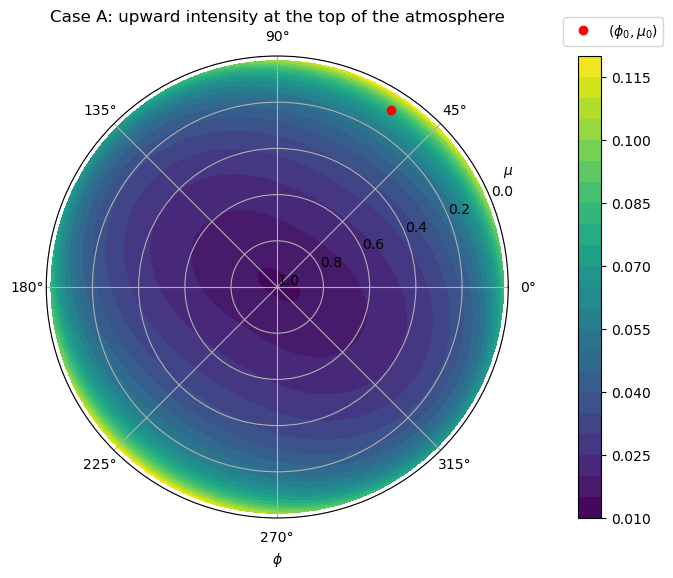

In [11]:
plot_TOA_upward_intensity(u_at_mu, phi0, "Case A: upward intensity at the top of the atmosphere")

----------

# Case B

As case A but with Henyey-Greenstein phase functions, which both codes delta-M scale.

**PythonicDISORT**

In [12]:
######################################### PYDISORT ARGUMENTS #######################################

g_arr = np.array([0.2, 0.5, 0.7, 0.8, 0.75, 0.6])  # Asymmetry parameter of each layer
Leg_coeffs_all = g_arr[:, None] ** np.arange(NQuad + 1)[None, :]  # Henyey-Greenstein phase functions

# Optional (used)
f_arr = Leg_coeffs_all[:, NQuad]  # Delta-M scaling, as in Stamnes' DISORT

# The other arguments are those of case A
####################################################################################################

In [13]:
# Call pydisort function
mu_arr, flux_up, flux_down, u0, u = PythonicDISORT.pydisort(
    tau_arr, omega_arr,
    NQuad,
    Leg_coeffs_all,
    mu0, I0, phi0,
    f_arr=f_arr,
    BDRF_Fourier_modes=BDRF_Fourier_modes,
    radii_arr=radii_arr,
)
# The intensity function at arbitrary polar angles
u_at_mu = PythonicDISORT.pydisort(
    tau_arr, omega_arr,
    NQuad,
    Leg_coeffs_all,
    mu0, I0, phi0,
    f_arr=f_arr,
    BDRF_Fourier_modes=BDRF_Fourier_modes,
    radii_arr=radii_arr,
    interpolate_mu=True,
)[-1]
solutions["B"] = dict(
    args=(tau_arr, omega_arr, NQuad, Leg_coeffs_all, mu0, I0, phi0),
    kwargs=dict(f_arr=f_arr, BDRF_Fourier_modes=BDRF_Fourier_modes),
    flux_up=flux_up, flux_down=flux_down, u_at_mu=u_at_mu, tau_BoA=tau_arr[-1],
)

**Stamnes' DISORT**

In [14]:
if disort_is_installed:
    disort_args = (tau_arr, omega_arr, NQuad, Leg_coeffs_all, phi0, BDRF_Fourier_modes[0], altitudes)
    rfldir, rfldn, flup, uu_nodes = run_disort(*disort_args, np.sort(mu_arr), phi, utau)
    uu = run_disort(*disort_args, umu, phi, utau)[-1]
    results.update(rfldirB=rfldir, rfldnB=rfldn, flupB=flup, uuB=uu, uu_nodesB=uu_nodes)

**Comparisons**

In [15]:
diffs = compare("B", "", mu_arr, flux_up, flux_down, u, u_at_mu)

upward flux: max difference / max = 1.39e-06
total downward flux: max difference / max = 2.25e-06
direct flux: max difference / max = 1.04e-05
diffuse downward flux: max difference / max = 2.20e-05
intensity at the quadrature nodes: max difference / max = 4.95e-06
intensity at other polar angles: max difference / max = 5.13e-06


**Does the test pass?**

With delta-M scaling, Stamnes' DISORT attenuates the direct beam along the slant paths of the delta-M scaled atmosphere, whereas PythonicDISORT uses the slant paths of the unscaled atmosphere, i.e. the true direct beam (section 3.8.1 of the Comprehensive Documentation). The split of the downward flux into its direct and diffuse parts therefore differs more than the other outputs, but the total downward flux does not.

In [16]:
assert diffs["upward flux"] < 5e-5
assert diffs["total downward flux"] < 5e-5
assert diffs["direct flux"] < 5e-4
assert diffs["diffuse downward flux"] < 5e-4
assert diffs["intensity at the quadrature nodes"] < 5e-5
assert diffs["intensity at other polar angles"] < 5e-5

print("The test passes")

The test passes


**Plots**

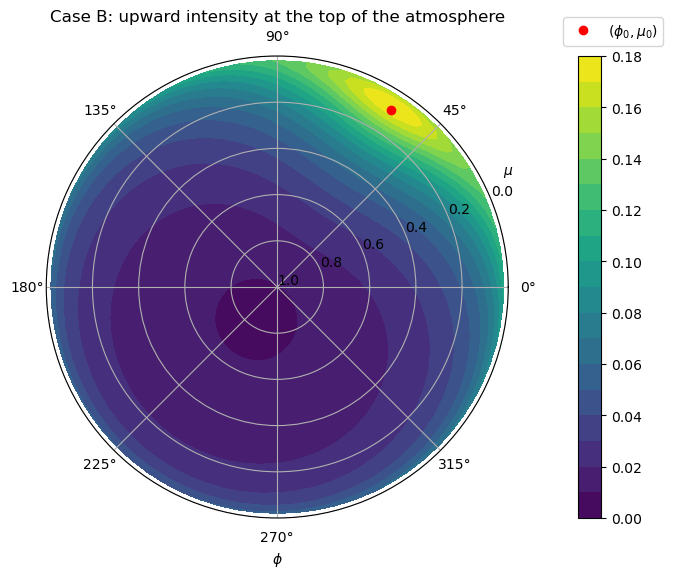

In [17]:
plot_TOA_upward_intensity(u_at_mu, phi0, "Case B: upward intensity at the top of the atmosphere")

----------

# Case C

Test problem 16 of Stamnes' DISORT: a 13-layer Rayleigh atmosphere at 412 nm between an altitude of 70 km and a black surface, with nearly conservative scattering and 30 streams. As in case A, neither code delta-M scales.

**PythonicDISORT**

In [18]:
######################################### PYDISORT ARGUMENTS #######################################

altitudes_C = np.array([70, 50, 40, 30, 24, 20, 16, 12, 10, 8, 6, 4, 2, 0])  # km
tau_arr_C = np.cumsum(np.array([
    0.234663486e-03, 0.765681267e-03, 0.315219164e-02, 0.598260760e-02, 0.857555866e-02, 0.162254870e-01,
    0.301396251e-01, 0.226671547e-01, 0.286127925e-01, 0.357458740e-01, 0.442614332e-01, 0.543503761e-01,
    0.665201172e-01,
]))
NLayers_C = len(tau_arr_C)
omega_arr_C = np.full(NLayers_C, 0.99999)
NQuad_C = 30
Leg_coeffs_all_C = np.zeros((NLayers_C, NQuad_C + 1))
Leg_coeffs_all_C[:, 0] = 1
Leg_coeffs_all_C[:, 2] = 0.47821149 / 5  # Rayleigh phase function with depolarization
phi0_C = 0

# Optional (used)
radii_arr_C = earth_radius + altitudes_C  # Pseudo-spherical correction

# Optional (unused)
f_arr = 0  # The moment of degree NQuad_C is zero
BDRF_Fourier_modes = []  # Black surface

####################################################################################################

In [19]:
# Call pydisort function
mu_arr, flux_up, flux_down, u0, u = PythonicDISORT.pydisort(
    tau_arr_C, omega_arr_C,
    NQuad_C,
    Leg_coeffs_all_C,
    mu0, I0, phi0_C,
    radii_arr=radii_arr_C,
)
# The intensity function at arbitrary polar angles
u_at_mu = PythonicDISORT.pydisort(
    tau_arr_C, omega_arr_C,
    NQuad_C,
    Leg_coeffs_all_C,
    mu0, I0, phi0_C,
    radii_arr=radii_arr_C,
    interpolate_mu=True,
)[-1]
solutions["C"] = dict(
    args=(tau_arr_C, omega_arr_C, NQuad_C, Leg_coeffs_all_C, mu0, I0, phi0_C),
    kwargs=dict(),
    flux_up=flux_up, flux_down=flux_down, u_at_mu=u_at_mu, tau_BoA=tau_arr_C[-1],
)

**Stamnes' DISORT**

In [20]:
# Test points: the polar angles and azimuths of test problem 16 (which uses only the upward polar angles and tau = 0)
angles_C = np.array([85.0, 80.0, 70.0, 60.0, 50.0, 40.0, 30.0, 20.0, 10.0, 0.0]) * pi / 180
umu_C = np.concatenate([-np.cos(angles_C[::-1]), np.cos(angles_C)])  # Both hemispheres, in increasing order
phi_C = np.array([0.0, 45.0, 90.0, 135.0, 180.0]) * pi / 180
utau_C = np.array([0.0, 0.002, 0.03, 0.15, 0.3, tau_arr_C[-1]])

In [21]:
if disort_is_installed:
    disort_args = (tau_arr_C, omega_arr_C, NQuad_C, Leg_coeffs_all_C, phi0_C, 0, altitudes_C)
    rfldir, rfldn, flup, uu_nodes = run_disort(*disort_args, np.sort(mu_arr), phi_C, utau_C)
    uu = run_disort(*disort_args, umu_C, phi_C, utau_C)[-1]
    results.update(umuC=umu_C, phiC=phi_C, utauC=utau_C)
    results.update(rfldirC=rfldir, rfldnC=rfldn, flupC=flup, uuC=uu, uu_nodesC=uu_nodes)

**Comparisons**

In [22]:
diffs = compare("C", "C", mu_arr, flux_up, flux_down, u, u_at_mu)

upward flux: max difference / max = 3.47e-05
total downward flux: max difference / max = 7.55e-06
direct flux: max difference / max = 2.21e-06
diffuse downward flux: max difference / max = 1.60e-05
intensity at the quadrature nodes: max difference / max = 4.56e-06
intensity at other polar angles: max difference / max = 5.04e-06


The upward flux differs the most. Stamnes' DISORT computes in single precision, and here its upward flux is not quite consistent with its own intensities. Because the phase function is Rayleigh, the intensity has only the Fourier modes 0, 1 and 2, so its azimuthal average follows exactly from the azimuths 0, 90 and 180 degrees, and integrating that over the upward quadrature nodes gives the upward flux.

In [23]:
# Double-Gauss quadrature on the upward hemisphere, which both codes use
nodes, weights = np.polynomial.legendre.leggauss(NQuad_C // 2)
nodes, weights = (nodes + 1) / 2, weights / 2
uu_up = results["uu_nodesC"][NQuad_C // 2 :]  # Upward nodes, in increasing order
azimuthal_average = (uu_up[..., 0] + uu_up[..., 4]) / 4 + uu_up[..., 2] / 2
flup_from_uu = 2 * pi * np.sum((nodes * weights)[:, None] * azimuthal_average, axis=0)

scale = np.max(results["flupC"])
print("Stamnes' DISORT, upward flux vs that from its own intensities: max difference / max =",
      f"{np.max(np.abs(results['flupC'] - flup_from_uu)) / scale:.2e}")
print("PythonicDISORT vs the upward flux from the intensities of Stamnes' DISORT: max difference / max =",
      f"{np.max(np.abs(flux_up(utau_C) - flup_from_uu)) / scale:.2e}")

Stamnes' DISORT, upward flux vs that from its own intensities: max difference / max = 2.73e-05
PythonicDISORT vs the upward flux from the intensities of Stamnes' DISORT: max difference / max = 7.87e-06


**Does the test pass?**

In [24]:
assert diffs["upward flux"] < 5e-5
assert diffs["total downward flux"] < 5e-5
assert diffs["direct flux"] < 5e-5
assert diffs["diffuse downward flux"] < 5e-5
assert diffs["intensity at the quadrature nodes"] < 5e-5
assert diffs["intensity at other polar angles"] < 5e-5

print("The test passes")

The test passes


**Plots**

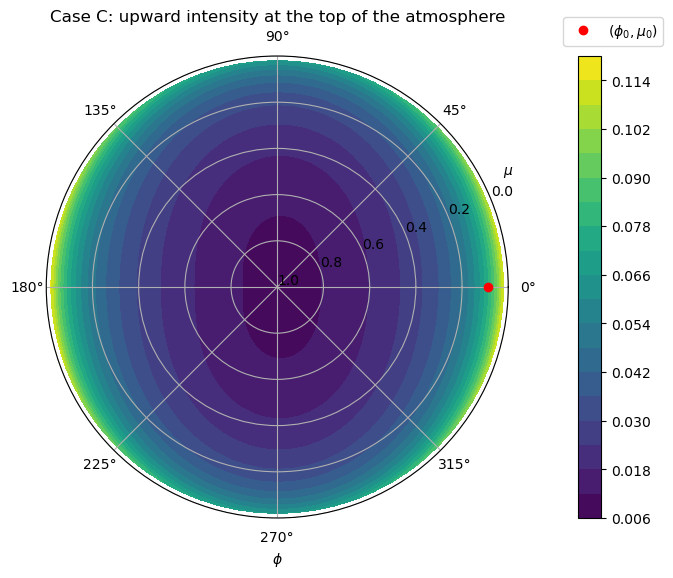

In [25]:
plot_TOA_upward_intensity(u_at_mu, phi0_C, "Case C: upward intensity at the top of the atmosphere")

----------

# Saving the results

With `save_results = True`, the results of Stamnes' DISORT from the cells above are saved to `Stamnes_results/PS_test.npz`, which `PS_test.py` and this notebook (without Stamnes' DISORT) load.

In [26]:
if save_results:
    if not disort_is_installed:
        raise RuntimeError("Stamnes' DISORT is required to generate the saved results")
    np.savez_compressed("Stamnes_results/PS_test", **results)
    print("Saved Stamnes_results/PS_test.npz")

----------

# Before and after the correction

We compare each solution above against the plane-parallel solution of the same atmosphere, i.e. without `radii_arr`.

In [27]:
def plane_parallel(case):
    # The plane-parallel solution of the atmosphere of a case, i.e. without `radii_arr`
    return PythonicDISORT.pydisort(*solutions[case]["args"], **solutions[case]["kwargs"])


print("Pseudo-spherical / plane-parallel (sun 5 degrees above the horizon)")
for case, sol in solutions.items():
    _, flux_up_PP, flux_down_PP, _, _ = plane_parallel(case)
    tau_BoA = sol["tau_BoA"]
    print(f"Case {case}:")
    print(f"  upward flux at the top of the atmosphere:  {sol['flux_up'](0) / flux_up_PP(0):.3f}")
    print(f"  total downward flux at the surface:        {np.sum(sol['flux_down'](tau_BoA)) / np.sum(flux_down_PP(tau_BoA)):.3f}")
    print(f"  direct flux at the surface:                {sol['flux_down'](tau_BoA)[1] / flux_down_PP(tau_BoA)[1]:.3g}")

Pseudo-spherical / plane-parallel (sun 5 degrees above the horizon)
Case A:
  upward flux at the top of the atmosphere:  1.176
  total downward flux at the surface:        1.224
  direct flux at the surface:                31.2
Case B:
  upward flux at the top of the atmosphere:  1.172
  total downward flux at the surface:        1.205
  direct flux at the surface:                31.2
Case C:
  upward flux at the top of the atmosphere:  1.094
  total downward flux at the surface:        1.144
  direct flux at the surface:                1.52


**Flux profiles (case C)**

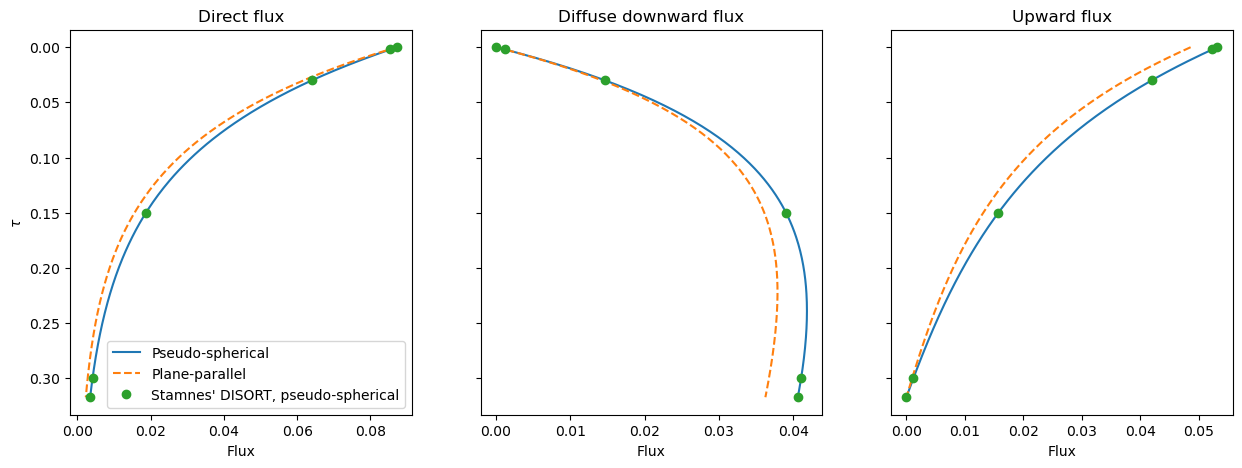

In [28]:
sol = solutions["C"]
_, flux_up_PP, flux_down_PP, _, _ = plane_parallel("C")
tau_plot = np.linspace(0, tau_arr_C[-1], 200)

fig, axs = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
panels = (
    ("Direct flux", lambda F_up, F_down: F_down(tau_plot)[1], "rfldirC"),
    ("Diffuse downward flux", lambda F_up, F_down: F_down(tau_plot)[0], "rfldnC"),
    ("Upward flux", lambda F_up, F_down: F_up(tau_plot), "flupC"),
)
for ax, (title, flux, key) in zip(axs, panels):
    ax.plot(flux(sol["flux_up"], sol["flux_down"]), tau_plot, label="Pseudo-spherical")
    ax.plot(flux(flux_up_PP, flux_down_PP), tau_plot, "--", label="Plane-parallel")
    ax.plot(results[key], results["utauC"], "o", label="Stamnes' DISORT, pseudo-spherical")
    ax.set_title(title)
    ax.set_xlabel("Flux")
axs[0].set_ylabel(r"$\tau$")
axs[0].invert_yaxis()
axs[0].legend()
plt.show()

**Upward intensity at the top of the atmosphere (case C)**

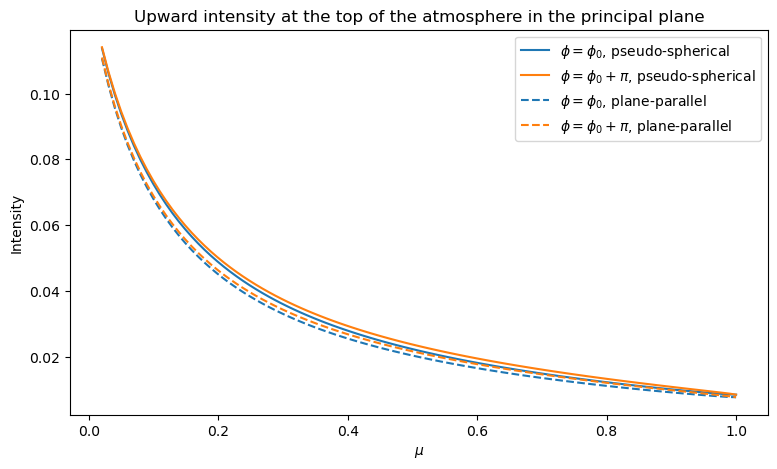

Pseudo-spherical / plane-parallel intensity: between 1.028 and 1.102


In [29]:
u_PP_at_mu = PythonicDISORT.pydisort(*sol["args"], interpolate_mu=True)[-1]
mu_plot = np.linspace(0.02, 1, 100)
phi_plot = np.array([phi0_C, phi0_C + pi])

fig, ax = plt.subplots(figsize=(9, 5))
for intensity, style, label in ((sol["u_at_mu"], "-", "pseudo-spherical"), (u_PP_at_mu, "--", "plane-parallel")):
    values = intensity(mu_plot, 0, phi_plot)
    ax.plot(mu_plot, values[:, 0], style, color="C0", label=r"$\phi = \phi_0$, " + label)
    ax.plot(mu_plot, values[:, 1], style, color="C1", label=r"$\phi = \phi_0 + \pi$, " + label)
ax.set_xlabel(r"$\mu$")
ax.set_ylabel("Intensity")
ax.set_title("Upward intensity at the top of the atmosphere in the principal plane")
ax.legend()
plt.show()

ratio = sol["u_at_mu"](mu_plot, 0, phi_plot) / u_PP_at_mu(mu_plot, 0, phi_plot)
print(f"Pseudo-spherical / plane-parallel intensity: between {ratio.min():.3f} and {ratio.max():.3f}")

**Dependence on the solar zenith angle (case C)**

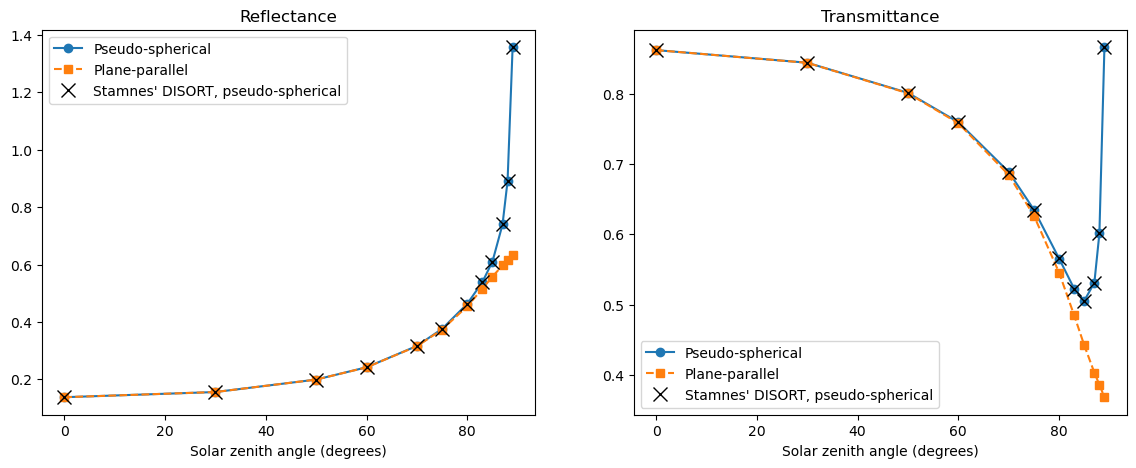

Solar zenith angle (degrees):                 [ 0 30 50 60 70 75 80 83 85 87 88 89]
Change of the reflectance by the correction (%): 0.00, 0.01, 0.03, 0.09, 0.29, 0.66, 1.93, 4.54, 9.37, 23.95, 45.05, 114.76
Reflectance + transmittance, pseudo-spherical:   [1.    1.    1.001 1.002 1.005 1.011 1.029 1.061 1.116 1.271 1.492 2.223]
Reflectance + transmittance, plane-parallel:     [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [30]:
sza_arr = np.array([0, 30, 50, 60, 70, 75, 80, 83, 85, 87, 88, 89])
reflectance = np.empty((2, len(sza_arr)))  # Upward flux at the top of the atmosphere / (mu0 * I0)
transmittance = np.empty((2, len(sza_arr)))  # Total downward flux at the surface / (mu0 * I0)
for j, sza in enumerate(sza_arr):
    mu0_sza = np.cos(sza * pi / 180)
    for i, radii in enumerate((radii_arr_C, None)):
        _, F_up, F_down, _ = PythonicDISORT.pydisort(
            tau_arr_C, omega_arr_C, NQuad_C, Leg_coeffs_all_C, mu0_sza, I0, phi0_C, only_flux=True, radii_arr=radii
        )
        reflectance[i, j] = F_up(0) / (mu0_sza * I0)
        transmittance[i, j] = np.sum(F_down(tau_arr_C[-1])) / (mu0_sza * I0)

if disort_is_installed:
    # Stamnes' DISORT with the pseudo-spherical correction
    reflectance_disort = np.empty(len(sza_arr))
    transmittance_disort = np.empty(len(sza_arr))
    for j, sza in enumerate(sza_arr):
        mu0_sza = np.cos(sza * pi / 180)
        rfldir, rfldn, flup, _ = run_disort(
            *disort_args, np.array([1.0]), np.array([0.0]), np.array([0, tau_arr_C[-1]]), mu0=mu0_sza
        )
        reflectance_disort[j] = flup[0] / (mu0_sza * I0)
        transmittance_disort[j] = (rfldir[1] + rfldn[1]) / (mu0_sza * I0)

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, quantity, title in zip(axs, (reflectance, transmittance), ("Reflectance", "Transmittance")):
    ax.plot(sza_arr, quantity[0], "o-", label="Pseudo-spherical")
    ax.plot(sza_arr, quantity[1], "s--", label="Plane-parallel")
    ax.set_xlabel("Solar zenith angle (degrees)")
    ax.set_title(title)
for ax, quantity in zip(axs, (reflectance_disort, transmittance_disort) if disort_is_installed else ()):
    ax.plot(sza_arr, quantity, "x", color="k", markersize=10, label="Stamnes' DISORT, pseudo-spherical")
for ax in axs:
    ax.legend()
plt.show()

print("Solar zenith angle (degrees):                ", sza_arr)
print("Change of the reflectance by the correction (%):", ", ".join(f"{x:.2f}" for x in 100 * (reflectance[0] / reflectance[1] - 1)))
print("Reflectance + transmittance, pseudo-spherical:  ", np.round(reflectance[0] + transmittance[0], 3))
print("Reflectance + transmittance, plane-parallel:    ", np.round(reflectance[1] + transmittance[1], 3))

**Explanation**

*Comparisons against Stamnes' DISORT.* In every case every output agrees to within $4 \times 10^{-5}$ of its maximum, i.e. to the single precision of Stamnes' DISORT. The two largest differences are explained in the cases above: the split of the downward flux into its direct and diffuse parts with delta-M scaling (case B), and the upward flux of Stamnes' DISORT in case C.

*What the correction changes.* In a plane-parallel atmosphere the beam crosses each layer along a path $1 / \mu_0$ times the thickness of the layer, which grows without bound as the sun approaches the horizon. Its path through the spherical shell is shorter, so with the correction more of the beam reaches each depth. With the sun 5 degrees above the horizon, the direct flux at the surface is 1.5 times larger in the thin atmosphere of case C, and 31 times larger (though negligible either way) in cases A and B. More of the beam is therefore scattered and the diffuse radiation increases: the upward flux at the top of the atmosphere by 17-18% in cases A and B and by 9% in case C, the total downward flux at the surface by 14-22%, and the upward intensity at the top of the atmosphere of case C by 3-10%.

*Dependence on the solar zenith angle.* The correction matters only for a low sun. In case C it changes the reflectance by less than 0.1% for solar zenith angles up to 60 degrees, by 2% at 80 degrees, by 9% at 85 degrees and by 24% at 87 degrees.

*Near the horizon.* The correction changes the attenuation of the beam but still treats each layer as horizontal and infinite, so it does not conserve energy: the reflected and transmitted fluxes no longer have to add up to the incident flux $\mu_0 I_0$ (minus the absorption), as they do in the plane-parallel atmosphere. Close to the horizon they exceed it: at a solar zenith angle of 89 degrees the reflectance of case C is 1.36, and the reflectance plus the transmittance is 2.2. Stamnes' DISORT gives the same values (the crosses in the plot above, which require Stamnes' DISORT), so results this close to the horizon should be interpreted with caution.